# Capstone Part 3
## Machine Learning and AI for a single traffic corridor

This notebook completes **Tasks 1–7** using the Part 2 hourly preparation rule and original UCI data. It contains actual trained-model results, clustering, association rules, a neural network, SHAP explanations, real MLflow tracking/versions, recommendations, API and monitoring simulations, and condition-based fairness results.

**Important:** no real accident dataset was sourced. Classification reproduces a documented traffic/weather **proxy**, not actual accident likelihood. High scores are not evidence of accident prediction performance.

### Open with Anaconda
Extract the full package to a folder, launch Jupyter Notebook/JupyterLab in the provided environment and open `Capstone_Part3.ipynb`. Keep all Python scripts and data folders beside the notebook. Choose **Run → Run All Cells**, or **Shift + Enter** for individual cells. No VS Code is needed.

Anaconda Prompt setup:
```text
conda env create -f environment.yml
conda activate capstone_part3
python -m jupyterlab Capstone_Part3.ipynb
```
The source data is bundled, so analysis does not download live data. The default notebook uses the supplied trained artifacts and reruns downstream tasks. Set `RETRAIN_MODELS=True` below to train and create new tracked runs. Saved outputs can be read without rerunning.

## 1 Setup and execution mode
Named loggers record progress; displayed tables and charts are user-facing results. Paths are located relative to the notebook/project rather than a fixed Windows directory. Only trusted bundled joblib artifacts are loaded.

The existing fitted models were trained through 2016, selected/stopped using 2017, and tested on 2018. Default review mode avoids unnecessary retraining.

In [1]:
from pathlib import Path
import sys, json, logging, subprocess, inspect
import pandas as pd
import numpy as np
import joblib
from IPython.display import display, Markdown, Code, Image
candidates=[Path.cwd(),Path.cwd()/"capstone_part3",Path.cwd().parent]
PROJECT=next((p.resolve() for p in candidates if (p/"run_all.py").is_file()),None)
if PROJECT is None:
    raise FileNotFoundError("Extract the complete capstone_part3 package and open the notebook there.")
if str(PROJECT) not in sys.path:sys.path.insert(0,str(PROJECT))
from logging_utils import configure_logging
configure_logging(PROJECT/"notebook.log")
logger=logging.getLogger(__name__)
from portable_tracking import relocate_tracking
relocate_tracking()
RETRAIN_MODELS=False
from run_all import run
logger.info("Notebook execution mode retrain=%s",RETRAIN_MODELS)
df, X, results, models, selected = run(reuse_models=not RETRAIN_MODELS)
OUT=PROJECT/"outputs"
display(pd.DataFrame({"Setting":["Python","Retrain models","Observed hours","Predictors"],
                      "Value":[sys.version.split()[0],RETRAIN_MODELS,len(df),X.shape[1]]}))

2026-11-22 15:27:40,788 | INFO | portable_tracking | Resolved MLflow artifact paths; updated 10 run URIs
2026-11-22 15:27:40,816 | INFO | __main__ | Notebook execution mode retrain=False
C:\ProgramData\miniconda3\envs\capstone_part3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-22 15:27:47,755 | INFO | data_features | Raw data loaded 48204 x 9
2026-11-22 15:27:47,765 | INFO | part2_cleaning | Schema validated: all 9 expected columns present
2026-11-22 15:27:47,924 | INFO | part2_cleaning | 0 rows affected: standardise holiday
2026-11-22 15:27:48,017 | INFO | part2_cleaning | 0 rows affected: standardise weather_main
2026-11-22 15:27:48,136 | WARNING | part2_cleaning | 1730 rows affected: standardise weather_description
2026-11-22 15:27:48,176 | INFO | part2_cleaning | 0 rows affected: drop invalid or non

,Setting,Value
0,Python,3.12.16
1,Retrain models,False
2,Observed hours,40575
3,Predictors,28


## 2 Data contract and chronological partitions

The cleaning pipeline preserves holiday `None`, removes exact duplicates, imputes impossible weather readings using training-period monthly medians, expands holiday flags within observed dates and selects one weather record per hour. Missing calendar hours are not fabricated.

Weather priority: Squall, Thunderstorm, Snow, Rain, Drizzle, Fog, Mist, Haze, Smoke, Clouds, Clear. This documented convention reproduces 3,133 proxy positives. The complete original ranking was not specified in the discussion, so matching counts alone does not prove all rows match another implementation.

Training: 2012–2016; validation: 2017; final test: Jan–Sep 2018. Scaling/imputation/model fits use training only. Model selection, operating thresholds and neural stopping use validation. The test partition is held out from selection.

In [2]:
display(pd.read_csv(OUT/"split_summary.csv"))
audit=json.loads((OUT/"data_audit.json").read_text())
display(pd.DataFrame({"Audit item":list(audit["audit"]),"Value":[str(v) for v in audit["audit"].values()]}))
assert len(df)==40575 and df.date_time.is_unique
assert len(X.columns)==28
assert not {"traffic_volume","high_risk","congestion_category"}.intersection(X.columns)
display(X.head())

,split,hours,positives,start,end
0,train,25329,1775,2012-10-02 09:00:00,2016-12-31 23:00:00
1,validation,8713,764,2017-01-01 00:00:00,2017-12-31 23:00:00
2,test,6533,594,2018-01-01 00:00:00,2018-09-30 23:00:00


,Audit item,Value
0,raw_rows,48204
1,raw_columns,9
2,collapse_rule,severe
3,weather_order,"['Squall', 'Thunderstorm', 'Snow', 'Rain', 'Dr..."
4,invalid_datetime_dropped,0
5,exact_duplicates_dropped,17
6,temp_imputed,10
7,rain_1h_imputed,1
8,snow_1h_imputed,0
9,clouds_all_imputed,0


,hour,day_of_week,is_weekend,is_holiday,temp_c,rain_1h,snow_1h,clouds_all,hour_sin,hour_cos,...,weather_drizzle,weather_fog,weather_mist,weather_haze,weather_smoke,weather_clouds,weather_clear,weather_unknown,is_low_visibility,is_severe_weather
0,9.0,1.0,0.0,0.0,15.13,0.0,0.0,40.0,7.071068e-01,-0.707107,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,10.0,1.0,0.0,0.0,16.21,0.0,0.0,75.0,5.000000e-01,-0.866025,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,11.0,1.0,0.0,0.0,16.43,0.0,0.0,90.0,2.588190e-01,-0.965926,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,12.0,1.0,0.0,0.0,16.98,0.0,0.0,90.0,1.224647e-16,-1.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,13.0,1.0,0.0,0.0,17.99,0.0,0.0,75.0,-2.588190e-01,-0.965926,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Task 1 Supervised demand and proxy models
### Label definitions

| Category | Fixed assignment rule |
|---|---|
| Low | volume ≤ 1248.5 |
| Medium | 1248.5 < volume ≤ 3427 |
| High | 3427 < volume ≤ 4952 |
| Severe | volume > 4952 |

Proxy positive means **volume >3427 AND selected weather in Thunderstorm, Snow, Squall, Fog, Mist, Haze or Smoke**. Exactly 3427 does not qualify. Part 1 congestion >5500 is separate. Full-hourly quartiles are inherited as a frozen assignment label contract, not claimed as training-only estimates. The audit also records training-only quartiles.

Both supervised tasks use the same 28 predictors: time/calendar, holiday, weather encodings, weather measurements, and cyclical hour/weekday/month coordinates. Current volume and traffic/risk categories are excluded from predictors.

In [3]:
display(df.groupby(["split","high_risk"]).size().unstack(fill_value=0))
label_count=int(df.high_risk.sum())
display(pd.DataFrame({"Measure":["Proxy positives","All hours","Percent positive"],"Value":[label_count,len(df),100*label_count/len(df)]}))
assert label_count==3133
from data_features import categories
display(pd.DataFrame({"Volume":[1248,1249,3427,3428,4952,4953],
                      "Category":categories(np.array([1248,1249,3427,3428,4952,4953]))}))

high_risk,0,1
split,,
test,5939,594
train,23554,1775
validation,7949,764


,Measure,Value
0,Proxy positives,3133.000000
1,All hours,40575.000000
2,Percent positive,7.721503


,Volume,Category
0,1248,Low
1,1249,Medium
2,3427,Medium
3,3428,High
4,4952,High
5,4953,Severe


### Regression comparison
Ridge is the linear baseline; random forest models nonlinear patterns. The neural demand model is evaluated on the same task. MAE is the typical absolute error in vehicles per observed hour; R-squared describes explained variation relative to a constant-mean baseline. Select the winner by **validation MAE**, not test results.

The problem uses observed same-hour weather. It is not a validated multi-step forecast with future weather forecasts.

,model,validation_mae,test_mae,test_r2,training_seconds,model_bytes
0,ridge_v1,797.421361,799.311195,0.738058,0.018870,1843
1,forest_reg_v2,239.270391,229.805218,0.961010,3.060729,10321916
4,neural_v3,377.340095,349.955207,0.935098,1.340437,144779


**Selected demand model:** `forest_reg_v2` using 2017 validation.

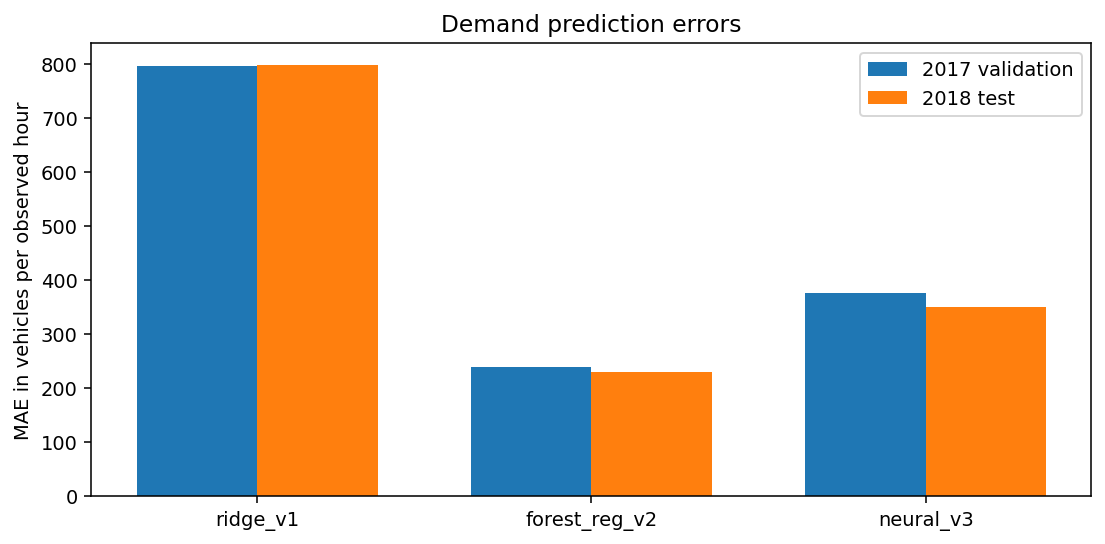

In [4]:
regression=results.loc[results.task.eq("regression"),["model","validation_mae","test_mae","test_r2","training_seconds","model_bytes"]]
display(regression)
display(Markdown(f"**Selected demand model:** `{selected['regression']}` using 2017 validation."))
display(Image(filename=str(OUT/"figures/01_regression_errors.png")))

### Proxy classification comparison
Train logistic regression and random forest with class weighting. Average precision summarises the precision–recall curve and supplements the requested accuracy, precision, recall, F1 and ROC AUC. Choose the classifier by **validation average precision**; choose its threshold using validation F1, then freeze that threshold for testing.

Scores are uncalibrated. The high AUC reflects the deterministic proxy definition and predictable daily volume patterns; it is not accident prediction skill.

,model,threshold,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc_average_precision
2,logistic_v1,0.817326,0.978723,0.829233,0.964646,0.891829,0.993872,0.923092
3,forest_cls_v2,0.499186,0.984846,0.863436,0.989899,0.922353,0.996692,0.948818


**Selected proxy classifier:** `forest_cls_v2`; threshold `0.49919`.

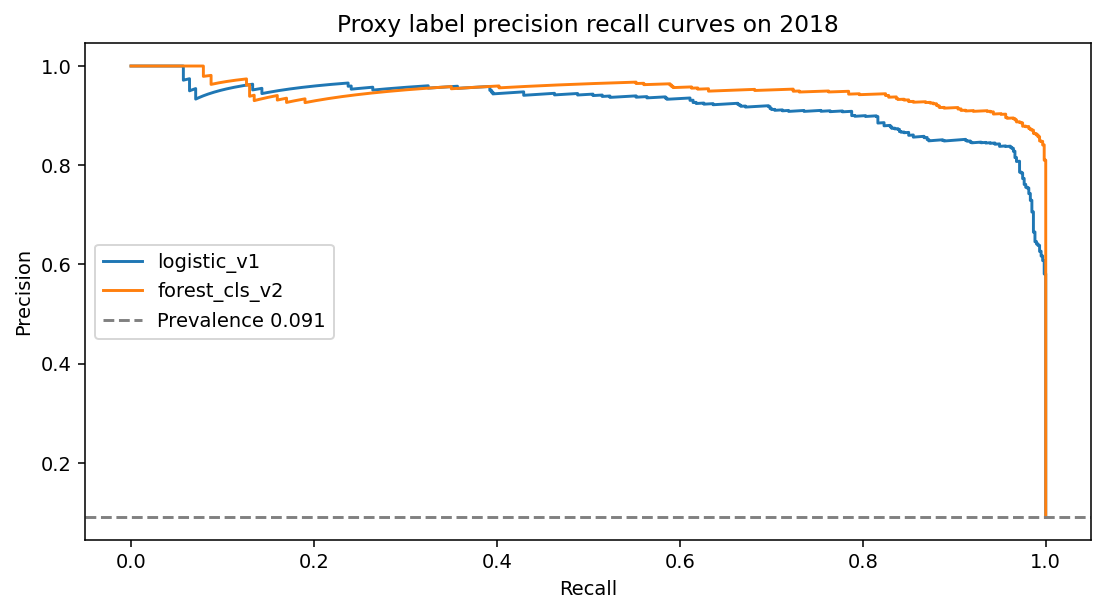

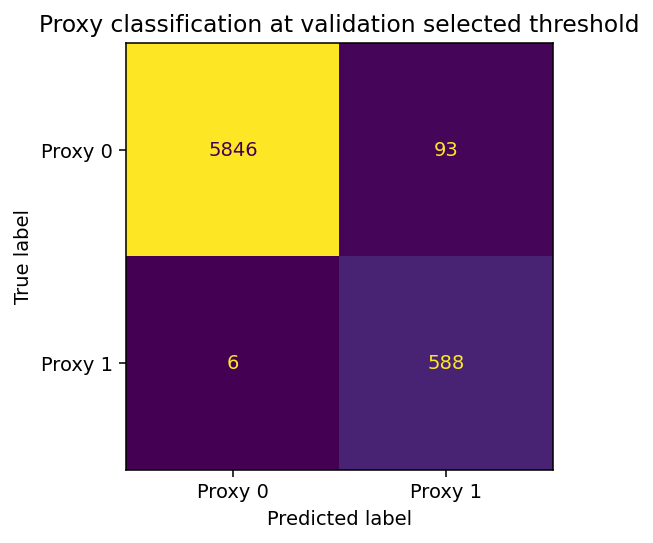

In [5]:
classification=results.loc[results.task.eq("classification"),["model","threshold","test_accuracy","test_precision","test_recall","test_f1","test_roc_auc","test_pr_auc_average_precision"]]
display(classification)
display(Markdown(f"**Selected proxy classifier:** `{selected['classification']}`; threshold `{selected['threshold']:.5f}`."))
display(Image(filename=str(OUT/"figures/02_precision_recall.png")))
display(Image(filename=str(OUT/"figures/03_confusion_matrix.png")))

## Task 2 Unsupervised traffic analysis
### K-means
Fit training-only scaled traffic volume, weather severity and cyclical hour. Compare k=3/4/5 on a seeded training sample by silhouette. The selected k=5 describes **traffic conditions**, not accidents.

Cluster names are intensity descriptions. Ordinal weather spacing affects distances; arithmetic mean hour can be misleading near midnight. Use cyclic plots and individual assignments when interpreting time.

,k,training_sample_silhouette
0,3,0.381785
1,4,0.364201
2,5,0.392520


,cluster,n,mean_volume,mean_hour,weekend_share,mean_temp,modal_weather,name
0,0,2966,4772.621376,12.700607,0.228591,280.558553,Rain,Peak traffic cluster 0
1,1,6475,1082.308571,8.031506,0.320309,278.264274,Clear,Quiet traffic cluster 1
2,2,6027,4746.195952,9.694043,0.245893,280.787333,Clouds,Very busy traffic cluster 2
3,3,6542,4343.979976,17.470193,0.287985,284.268153,Clouds,Busy traffic cluster 3
4,4,3319,1264.143417,8.814703,0.332329,280.235523,Rain,Moderate traffic cluster 4


,cluster,n,mean_volume
0,0,924,4661.483766
1,1,1480,1112.622297
2,2,1491,4817.144199
3,3,1635,4449.225688
4,4,1003,1300.407777


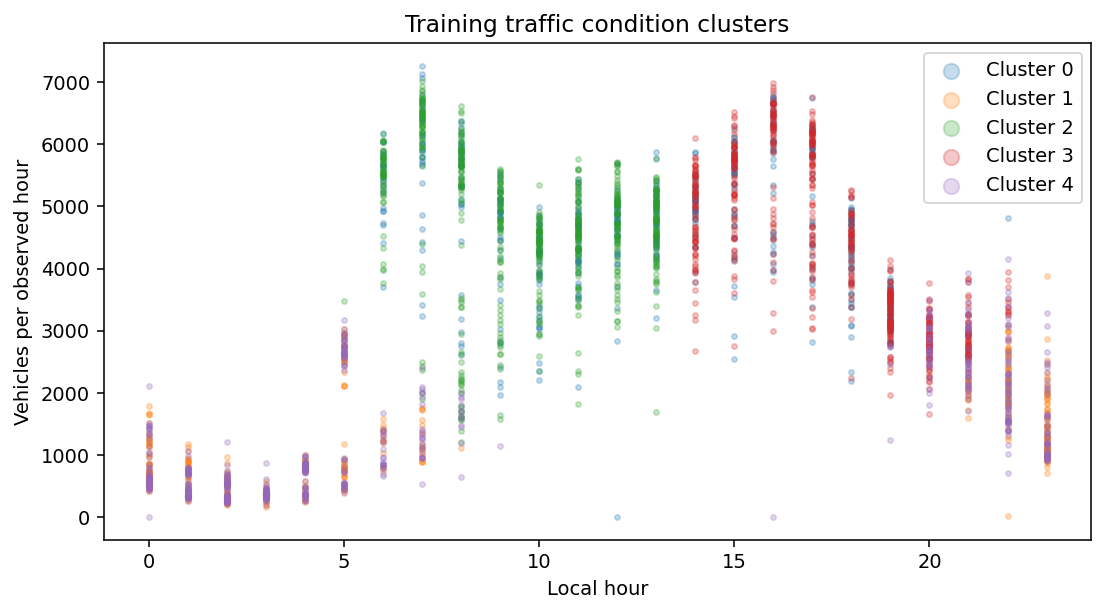

In [6]:
display(pd.read_csv(OUT/"cluster_selection.csv"))
display(pd.read_csv(OUT/"cluster_profiles.csv"))
display(pd.read_csv(OUT/"test_cluster_profiles.csv"))
display(Image(filename=str(OUT/"figures/05_traffic_clusters.png")))

### Association rule mining
Enumerate antecedents from time period, day type and weather, with congestion category only as consequent. Support is the proportion of all training hours with both antecedent and consequent. Confidence is P(consequent | antecedent). Lift is confidence divided by the consequent's training prevalence.

Gates: antecedent n≥50, joint n≥30, support≥0.005 and lift>1. Sort by training lift; test confidence and lift are diagnostic only. High lift with little support is not a causal policy recommendation.

In [7]:
rules=pd.read_csv(OUT/"association_rules.csv")
display(rules.head(12))
r=rules.iloc[0]
display(Markdown(f"The highest-training-lift rule is **{r.antecedent} → {r.consequent}**. "
    f"Training confidence is **{r.confidence:.1%}**, lift **{r.lift:.2f}**, joint count **{int(r.joint_n)}**. "
    f"Its 2018 antecedent support is **{int(r.test_antecedent_n)} hours**, so holdout stability still needs caution."))

,antecedent,consequent,support,confidence,lift,antecedent_n,joint_n,test_antecedent_n,test_confidence,test_lift
0,time_period=Overnight AND day_type=Weekend AND...,congestion=Low,0.005053,0.992248,3.899558,129,128,40,0.925000,3.760439
1,time_period=Overnight AND day_type=Weekend AND...,congestion=Low,0.020569,0.917254,3.604828,568,521,73,0.904110,3.675512
2,time_period=Overnight AND day_type=Weekend,congestion=Low,0.065656,0.910235,3.577246,1827,1663,460,0.895652,3.641130
3,time_period=Morning AND day_type=Weekday AND w...,congestion=Severe,0.009791,0.873239,3.546870,284,248,106,0.933962,3.738710
4,time_period=Overnight AND day_type=Weekend AND...,congestion=Low,0.023688,0.900901,3.540562,666,600,221,0.873303,3.550274
5,time_period=Overnight AND weather_main=Snow,congestion=Low,0.015397,0.890411,3.499336,438,390,128,0.828125,3.366609
6,time_period=Morning AND day_type=Weekday AND w...,congestion=Severe,0.011647,0.860058,3.493332,343,295,106,0.867925,3.474357
7,time_period=Overnight AND day_type=Weekend AND...,congestion=Low,0.006277,0.883333,3.471521,180,159,44,0.863636,3.510975
8,time_period=Morning AND day_type=Weekday AND w...,congestion=Severe,0.026886,0.840741,3.414869,810,681,258,0.837209,3.351402
9,time_period=Overnight AND weather_main=Clear,congestion=Low,0.075684,0.866245,3.404363,2213,1917,747,0.856760,3.483021


The highest-training-lift rule is **time_period=Overnight AND day_type=Weekend AND weather_main=Snow → congestion=Low**. Training confidence is **99.2%**, lift **3.90**, joint count **128**. Its 2018 antecedent support is **40 hours**, so holdout stability still needs caution.

## Task 3 Neural demand prediction with explainability
### Network and stopping
The chosen allowed option is a neural network for demand prediction, with three hidden layers **64 → 32 → 16**, ReLU and Adam. Training-only input/target scalers are used. A manual partial-fit loop evaluates chronological 2017 validation every epoch and retains the best checkpoint; no random internal validation split is used.

Best epoch is 12; 24 epochs were run with patience 12. The forest performs better on this comparison, so the neural model is not promoted solely for complexity.

,Property,Value
0,Hidden layers,"(64, 32, 16)"
1,Best epoch,12
2,Epochs run,24


,epoch,training_loss_standardised,validation_mae
19,20,0.033827,524.701839
20,21,0.032697,381.957671
21,22,0.031825,521.657374
22,23,0.034938,401.442215
23,24,0.031155,481.583660


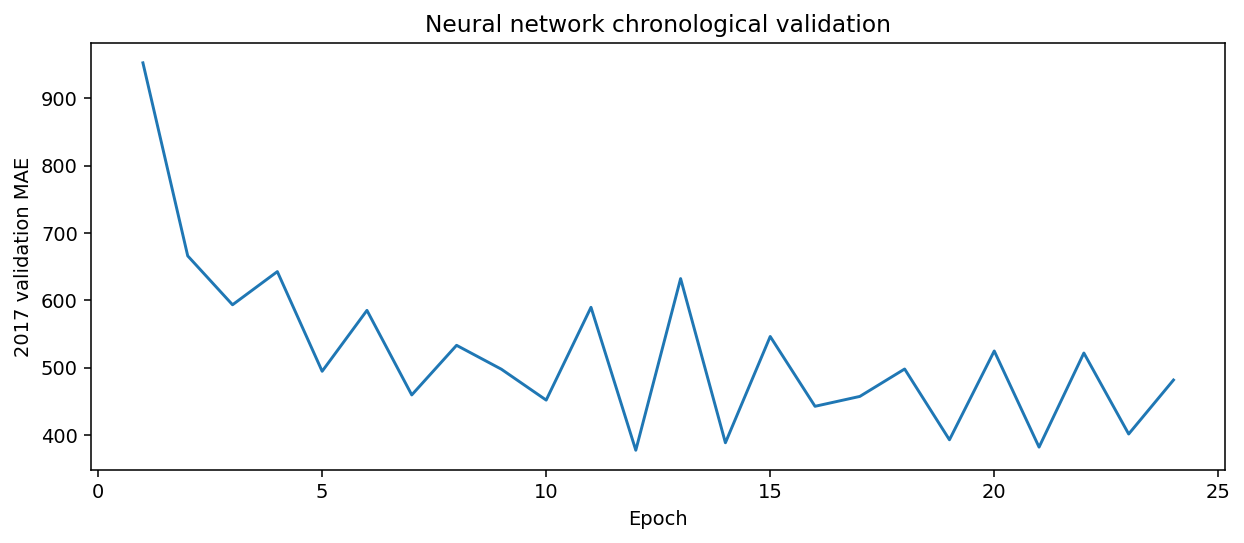

In [8]:
from modeling import DenseDemandModel
neural=models["neural_v3"]
display(pd.DataFrame({"Property":["Hidden layers","Best epoch","Epochs run"],
                      "Value":[str(neural.net.hidden_layer_sizes),neural.best_epoch,len(neural.history)]}))
display(pd.read_csv(OUT/"neural_training_history.csv").tail())
display(Image(filename=str(OUT/"figures/04_neural_history.png")))

### SHAP on a comparable demand model
Tree SHAP explains the random-forest demand model trained on the same problem and predictors. It is **not a direct explanation of the neural weights**. The fixed sample is 150 test hours; RF/neural prediction agreement is measured and reported. Strong agreement does not make the models identical.

Hour-related fields dominate the mean absolute attributions. Correlated time encodings share information, and SHAP attributions are not causal effects.

,feature,mean_absolute_shap_vehicles
0,hour_cos,1441.154823
1,hour,414.848401
2,hour_sin,204.981064
3,is_weekend,164.856756
4,dow_sin,140.338998
5,day_of_week,114.735095
6,is_holiday,66.553760
7,temp_c,57.711595
8,dow_cos,48.917583
9,month_cos,46.480538


{'explained_model': 'forest_reg_v2',
 'deep_model': 'neural_v3',
 'test_agreement_r2_neural_as_reference': 0.9559407585040811,
 'mean_absolute_prediction_disagreement': 286.5286021528629,
 'shap_sample_hours': 150,
 'scope': 'Comparable model for same demand task and features, not direct neural explanation or causal attribution.'}

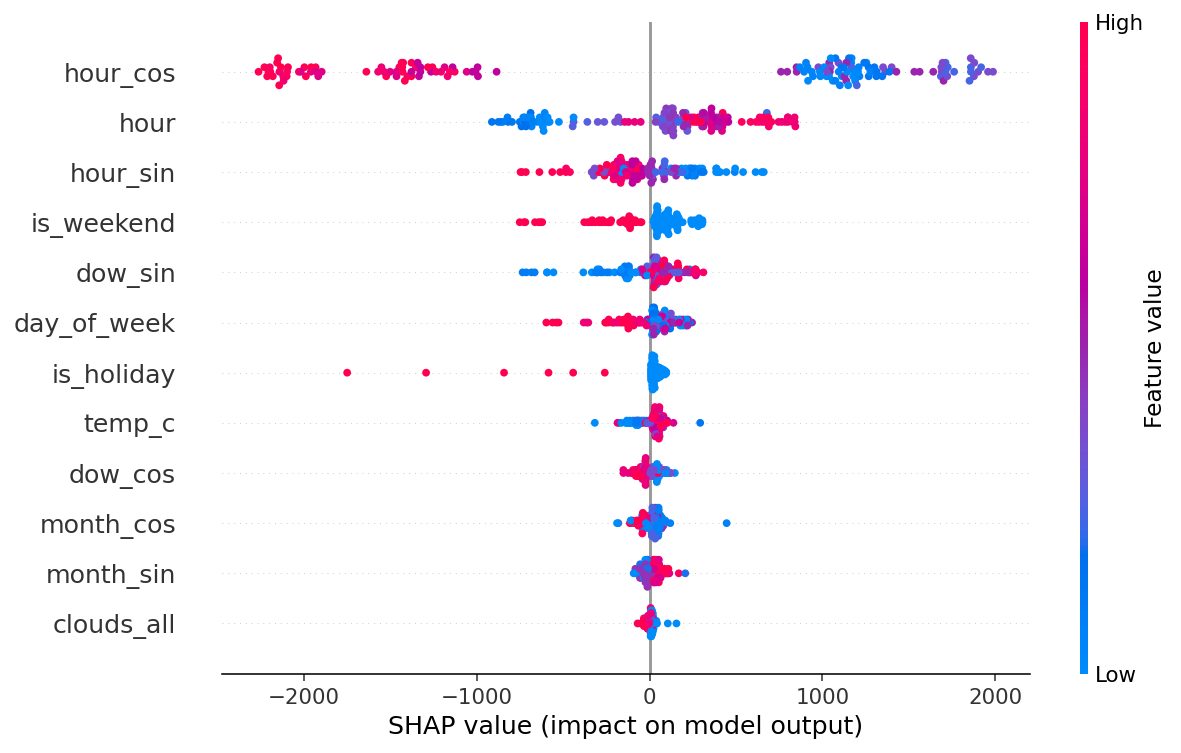

In [9]:
display(pd.read_csv(OUT/"shap_importance.csv").head(12))
display(json.loads((OUT/"explanation_scope.json").read_text()))
display(Image(filename=str(OUT/"figures/06_shap_demand.png")))

## Task 4 Advanced AI with MLflow
MLflow is selected for reproducible experiment comparison and model lineage. Actual runs record parameters, scores, fit times, artifact sizes and model files. The SQLite store and artifacts are included. Repeated training creates additional runs/versions.

The registry stores joblib artifacts rather than managed pyfunc packages. Tracking does not make a weak proxy valid or guarantee operational safety. The relocation helper resolves local paths after extraction.

In [10]:
from modeling import configure_tracking
mlflow, client=configure_tracking()
experiment=client.get_experiment_by_name("Capstone_Part3_Mobility")
runs=mlflow.search_runs(experiment_ids=[experiment.experiment_id])
columns=["run_id","tags.mlflow.runName","params.task","metrics.validation_mae","metrics.test_mae","metrics.test_f1","metrics.test_pr_auc_average_precision"]
display(runs[[col for col in columns if col in runs.columns]].head(10))
versions=json.loads((OUT/"model_versions.json").read_text())
display(pd.DataFrame(versions))

,run_id,tags.mlflow.runName,params.task,metrics.validation_mae,metrics.test_mae,metrics.test_f1,metrics.test_pr_auc_average_precision
0,cb82a3b87e7e44b6a056f988987473a4,neural_v3,regression,377.340095,349.955207,NaN,NaN
1,2343bd53519141f59b64ef6dcb0a653c,forest_cls_v2,classification,NaN,NaN,0.922353,0.948818
2,76124ebfe9624bae9d1bd9373ed61f6d,logistic_v1,classification,NaN,NaN,0.891829,0.923092
3,16dd6484f6d44235aa0122c067101d2f,forest_reg_v2,regression,239.270391,229.805218,NaN,NaN
4,490880b4ed9c47ce8da6eb875243ee21,ridge_v1,regression,797.421361,799.311195,NaN,NaN
5,e6067f17a7f94c3fb11fe2ef0ed2d6be,neural_v3,regression,377.340095,349.955207,NaN,NaN
6,a455dad61bce494882428476be15c63a,forest_cls_v2,classification,NaN,NaN,0.922353,0.948818
7,8242eb05b9d64f9b875d4f7be7938767,logistic_v1,classification,NaN,NaN,0.891829,0.923092
8,8384f746fb744b7faebb8d1e3b1874d8,forest_reg_v2,regression,239.270391,229.805218,NaN,NaN
9,907b68641e764c0cbf5acdbfd3f9fc97,ridge_v1,regression,797.421361,799.311195,NaN,NaN


,model_id,task,registry,version,run_id,artifact,threshold,training_seconds
0,ridge_v1,regression,TrafficVolume,4,490880b4ed9c47ce8da6eb875243ee21,models/ridge_v1.joblib,NaN,0.018870
1,forest_reg_v2,regression,TrafficVolume,5,16dd6484f6d44235aa0122c067101d2f,models/forest_reg_v2.joblib,NaN,3.060729
2,logistic_v1,classification,ProxyRisk,3,76124ebfe9624bae9d1bd9373ed61f6d,models/logistic_v1.joblib,0.817326,0.047640
3,forest_cls_v2,classification,ProxyRisk,4,2343bd53519141f59b64ef6dcb0a653c,models/forest_cls_v2.joblib,0.499186,0.957143
4,neural_v3,regression,TrafficVolume,6,cb82a3b87e7e44b6a056f988987473a4,models/neural_v3.joblib,NaN,1.340437


## Task 5 Travel-window recommendations
This dataset describes one corridor, so recommend timing rather than alternative routes. Rank permitted one-hour windows using equal weights on training historical means and selected-model predictions. Weather/day-type/hour groups need n≥20; otherwise fall back to day-type/hour and log the limitation. Other weather inputs use historical medians.

Change the variables in the next cell to explore a window. Holiday status must be supplied explicitly. This is not live routing, measured travel time or a safety guarantee.

In [11]:
from recommendation import recommend
JOURNEY_DATE="2018-06-18"
WEATHER="Clear"
START_HOUR=7
END_HOUR=12
IS_HOLIDAY=False
recommendation=recommend(JOURNEY_DATE,WEATHER,START_HOUR,END_HOUR,IS_HOLIDAY)
display(Markdown(recommendation["recommendation"]))
display(pd.DataFrame(recommendation["candidates"]))

2026-11-22 15:28:34,739 | INFO | recommendation | Recommendation generated for date=2018-06-18 weather=Clear window=7–12


For the weekday journey on 2018-06-18, consider 10:00–11:00 within your permitted window. Historical support averages 4,458 vehicles/hour (n=211); the demand model estimates 4,389. Weather scenario: Clear; other weather inputs use historical medians. This ranks travel timing on one corridor, not alternative routes; lower volume does not guarantee less delay or safer travel.

,hour,historical_mean,n,support_scope,model_prediction,ranking_score
0,10,4458.094787,211,"day type, hour and weather",4388.734493,4423.414640
1,11,4730.397196,214,"day type, hour and weather",4584.922193,4657.659694
2,9,4954.250000,204,"day type, hour and weather",4909.267905,4931.758953
3,8,5550.202128,188,"day type, hour and weather",5938.974141,5744.588135
4,7,5997.746032,189,"day type, hour and weather",6566.379613,6282.062823


## Task 6 MLOps and deployment simulation

This section brings **all five Task 6 requirements together**. Run the setup cell first, then run these cells in order. Existing saved outputs show the supplied experiment results; `RETRAIN_MODELS=False` reuses them, while `True` retrains and creates new MLflow records.

### 6.1 Model versioning

The table below identifies each model artifact, task, MLflow registry version and experiment run. Performance is also documented here:

| Model ID | Registry/version in supplied run | Test performance |
|---|---|---|
| ridge_v1 | TrafficVolume / 4 | MAE 799.31; R² 0.7381 |
| forest_reg_v2 | TrafficVolume / 5 | MAE 229.81; R² 0.9610 |
| neural_v3 | TrafficVolume / 6 | MAE 349.96; R² 0.9351 |
| logistic_v1 | ProxyRisk / 3 | F1 0.8918; ROC AUC 0.9939 |
| forest_cls_v2 | ProxyRisk / 4 | F1 0.9224; ROC AUC 0.9967 |

Model IDs are project labels; MLflow version numbers are generated within each registry family and may increase on retraining. Select models using validation results, not these test scores. The supplied selected demand and proxy models are the two forests.

### 6.2 Experiment tracking with MLflow

The next cell displays actual experiment runs followed by the version manifest. This deliberately repeats Task 4's tracking evidence so Task 6 can be reviewed in one place.

- **Experiments:** `Capstone_Part3_Mobility` groups related training runs.
- **Parameters:** model settings and task are recorded for each run.
- **Metrics:** validation/test scores, fit time and artifact size support comparison.
- **Versions:** registered model versions link to run IDs and saved joblib artifacts.

Records are stored in `mlflow.db`, with model artifacts in `mlartifacts/` and the version manifest in `outputs/model_versions.json`. A missing metric for an inapplicable task is not a failed run (for example, regression has no F1 score).

The display below is a compact view. For full parameters, inspect a run in MLflow. The optional UI requires the full MLflow package in your Anaconda environment:

```text
python -m pip install mlflow==3.17.2
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Run these commands from the extracted project folder, then open `http://127.0.0.1:5000`. The UI itself was not browser-tested in the supplied execution environment.


In [12]:
from modeling import configure_tracking
mlflow, client=configure_tracking()
experiment=client.get_experiment_by_name("Capstone_Part3_Mobility")
runs=mlflow.search_runs(experiment_ids=[experiment.experiment_id])
columns=["run_id","tags.mlflow.runName","params.task","metrics.validation_mae","metrics.test_mae","metrics.test_f1","metrics.test_pr_auc_average_precision"]
display(runs[[col for col in columns if col in runs.columns]].head(10))
versions=json.loads((OUT/"model_versions.json").read_text())
display(pd.DataFrame(versions))

,run_id,tags.mlflow.runName,params.task,metrics.validation_mae,metrics.test_mae,metrics.test_f1,metrics.test_pr_auc_average_precision
0,cb82a3b87e7e44b6a056f988987473a4,neural_v3,regression,377.340095,349.955207,NaN,NaN
1,2343bd53519141f59b64ef6dcb0a653c,forest_cls_v2,classification,NaN,NaN,0.922353,0.948818
2,76124ebfe9624bae9d1bd9373ed61f6d,logistic_v1,classification,NaN,NaN,0.891829,0.923092
3,16dd6484f6d44235aa0122c067101d2f,forest_reg_v2,regression,239.270391,229.805218,NaN,NaN
4,490880b4ed9c47ce8da6eb875243ee21,ridge_v1,regression,797.421361,799.311195,NaN,NaN
5,e6067f17a7f94c3fb11fe2ef0ed2d6be,neural_v3,regression,377.340095,349.955207,NaN,NaN
6,a455dad61bce494882428476be15c63a,forest_cls_v2,classification,NaN,NaN,0.922353,0.948818
7,8242eb05b9d64f9b875d4f7be7938767,logistic_v1,classification,NaN,NaN,0.891829,0.923092
8,8384f746fb744b7faebb8d1e3b1874d8,forest_reg_v2,regression,239.270391,229.805218,NaN,NaN
9,907b68641e764c0cbf5acdbfd3f9fc97,ridge_v1,regression,797.421361,799.311195,NaN,NaN


,model_id,task,registry,version,run_id,artifact,threshold,training_seconds
0,ridge_v1,regression,TrafficVolume,4,490880b4ed9c47ce8da6eb875243ee21,models/ridge_v1.joblib,NaN,0.018870
1,forest_reg_v2,regression,TrafficVolume,5,16dd6484f6d44235aa0122c067101d2f,models/forest_reg_v2.joblib,NaN,3.060729
2,logistic_v1,classification,ProxyRisk,3,76124ebfe9624bae9d1bd9373ed61f6d,models/logistic_v1.joblib,0.817326,0.047640
3,forest_cls_v2,classification,ProxyRisk,4,2343bd53519141f59b64ef6dcb0a653c,models/forest_cls_v2.joblib,0.499186,0.957143
4,neural_v3,regression,TrafficVolume,6,cb82a3b87e7e44b6a056f988987473a4,models/neural_v3.joblib,NaN,1.340437


### 6.2a Start the actual MLflow web UI from Jupyter

Run the next two cells after the notebook setup. They use the real MLflow application and the included `mlflow.db`; this is not a screenshot or imitation dashboard. The first cell installs the full MLflow package into this notebook's Python environment only if needed. Installation requires an internet connection and may take a few minutes.

The second cell starts a background server on your own computer at **http://127.0.0.1:5000**, waits for it to respond, and displays a clickable link. Keep the Jupyter kernel running. The server is local to your computer. If port 5000 is already occupied, change `MLFLOW_UI_PORT` to 5001 and rerun. No VS Code is needed.


In [13]:
# Install the full UI package if this environment only has mlflow-skinny.
import importlib.metadata as package_metadata
import subprocess, sys, logging
logger = logging.getLogger(__name__)
try:
    full_mlflow_version = package_metadata.version("mlflow")
    logger.info("Full MLflow package available: %s", full_mlflow_version)
except package_metadata.PackageNotFoundError:
    logger.info("Installing full MLflow 3.17.2 for the web UI; please wait")
    subprocess.run([sys.executable, "-m", "pip", "install", "mlflow==3.17.2"], check=True)
    logger.info("Full MLflow installation completed")


2026-11-22 15:28:34,906 | INFO | __main__ | Installing full MLflow 3.17.2 for the web UI; please wait
2026-11-22 15:30:31,374 | INFO | __main__ | Full MLflow installation completed


In [14]:
# Start the real MLflow UI without blocking the notebook.
import socket, time, urllib.request, html
from IPython.display import HTML, display
MLFLOW_UI_PORT = 5000
MLFLOW_UI_URL = f"http://127.0.0.1:{MLFLOW_UI_PORT}"
if "mlflow_ui_process" in globals() and mlflow_ui_process.poll() is None:
    logger.info("This kernel already owns an MLflow UI process; stop it before changing ports")
    display(HTML(f'<a href="{html.escape(mlflow_ui_active_url)}" target="_blank">Open the running MLflow UI</a>'))
else:
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as probe:
        probe.bind(("127.0.0.1", MLFLOW_UI_PORT))
    ui_log_path = PROJECT / "mlflow_ui.log"
    command = [sys.executable, "-m", "mlflow", "ui",
               "--backend-store-uri", "sqlite:///" + str((PROJECT / "mlflow.db").resolve()),
               "--host", "127.0.0.1", "--port", str(MLFLOW_UI_PORT)]
    with ui_log_path.open("a", encoding="utf-8") as ui_log:
        mlflow_ui_process = subprocess.Popen(command, cwd=str(PROJECT),
            stdout=ui_log, stderr=subprocess.STDOUT)
    mlflow_ui_active_url = MLFLOW_UI_URL
    logger.info("Starting MLflow UI; server output: %s", ui_log_path)
    ui_ready = False
    deadline = time.monotonic() + 45
    while time.monotonic() < deadline:
        if mlflow_ui_process.poll() is not None:
            raise RuntimeError(f"MLflow UI stopped. Read {ui_log_path} for details.")
        try:
            with urllib.request.urlopen(MLFLOW_UI_URL + "/health", timeout=1) as response:
                ui_ready = response.status == 200
        except (OSError, urllib.error.URLError):
            pass
        if ui_ready:
            break
        time.sleep(0.5)
    if ui_ready:
        logger.info("MLflow UI ready at %s", MLFLOW_UI_URL)
        display(HTML(f'<a href="{html.escape(MLFLOW_UI_URL)}" target="_blank"><b>Open actual MLflow UI</b></a>'))
    else:
        logger.warning("MLflow UI is still starting; inspect %s and try the link shortly", ui_log_path)
        display(HTML(f'<a href="{html.escape(MLFLOW_UI_URL)}" target="_blank">Try MLflow UI</a>'))


2026-11-22 15:30:31,458 | INFO | __main__ | Starting MLflow UI; server output: E:\FINAL CAPSTONE PROJECT\smart-city-traffic-capstone\part3_machine_learning\mlflow_ui.log
2026-11-22 15:31:01,860 | INFO | __main__ | MLflow UI ready at http://127.0.0.1:5000


### 6.2b Inspect and compare your actual experiments

1. Click **Open actual MLflow UI** above.
2. Open the experiment **Capstone_Part3_Mobility**. Supplied runs should already appear; retraining is not required to view them.
3. Open a run to review **Parameters**, **Metrics** and **Artifacts**. The logged joblib model is under the run's artifacts.
4. Select regression runs and choose **Compare**. Compare `validation_mae`, `test_mae` and R-squared metrics. Lower MAE is better.
5. Compare classification runs separately using precision, recall, F1, ROC AUC and average precision. Higher is better for these metrics; model selection uses validation scores.
6. Open the **Models** area to inspect the **TrafficVolume** and **ProxyRisk** registered models, their versions and linked runs. Navigation wording can vary by MLflow release.
7. If evidence is needed for your submission, capture your own screenshots of the experiment list, run comparison and registered versions after opening the real UI.

The existing table under 6.2 remains a convenient notebook summary. The web UI reads the same tracking database. These launcher cells have not been executed in the supplied notebook because this execution environment does not permit local server sockets; run them in Anaconda/Jupyter on your Windows computer. No UI screenshot or live hosting is claimed here.

### 6.2c Stop the UI when finished (optional)

Run the following cell only when you want to close the server. It stops only the process started by this notebook. To keep the UI open during **Run All**, leave `STOP_MLFLOW_UI=False`.


In [15]:
STOP_MLFLOW_UI = False
if STOP_MLFLOW_UI and "mlflow_ui_process" in globals() and mlflow_ui_process.poll() is None:
    mlflow_ui_process.terminate()
    try:
        mlflow_ui_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        mlflow_ui_process.kill()
        mlflow_ui_process.wait(timeout=5)
    logger.info("Notebook-owned MLflow UI stopped")


### 6.3 Deployment: FastAPI model-serving mock
FastAPI accepts a validated timestamp and weather fields and returns predicted demand, an uncalibrated proxy score, label and selected model IDs. It rejects invalid weather, bad dates, impossible values and supplied target columns. The simulation uses a real in-process FastAPI TestClient; no production hosting or public endpoint is claimed.

To launch locally on your computer later: `python serve.py`, then open `http://127.0.0.1:8000/docs`. This notebook does not start a blocking server.

In [16]:
from api import simulate_api
api_evidence=simulate_api()
display(api_evidence)
assert api_evidence["status_code"]==200
assert api_evidence["invalid_date_status"]==422
assert api_evidence["forbidden_target_status"]==422

2026-11-22 15:31:02,183 | INFO | api | Prediction served timestamp=2018-06-18 08:00:00 weather=Clear
2026-11-22 15:31:02,188 | INFO | httpx | HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"
2026-11-22 15:31:02,195 | INFO | httpx | HTTP Request: POST http://testserver/predict "HTTP/1.1 422 Unprocessable Entity"
2026-11-22 15:31:02,203 | INFO | httpx | HTTP Request: POST http://testserver/predict "HTTP/1.1 422 Unprocessable Entity"
2026-11-22 15:31:02,206 | WARNING | api | API validation simulation rejected malformed date and forbidden target input with HTTP 422


{'method': 'FastAPI TestClient in-process; network listener not required or tested',
 'request': {'date_time': '2018-06-18T08:00:00',
  'weather_main': 'Clear',
  'temp': 288.15,
  'rain_1h': 0,
  'snow_1h': 0,
  'clouds_all': 20,
  'is_holiday': False},
 'response': {'predicted_vehicles_per_hour': 5928.45997434053,
  'proxy_positive_score_uncalibrated': 0.019547202427122122,
  'proxy_label_at_validation_threshold': 0,
  'threshold': 0.4991858223219664,
  'regression_version': 'forest_reg_v2',
  'classification_version': 'forest_cls_v2',
  'actual_accident_prediction': False,
  'limitations': 'Observed-condition volume estimate and deterministic assignment proxy; not a safety or travel-time guarantee.'},
 'status_code': 200,
 'invalid_date_status': 422,
 'forbidden_target_status': 422}

### 6.4 Monitoring: feature and prediction-error drift
Compare 2018 against the 2017 validation reference. Fixed heuristic alerts: feature PSI>0.20 or demand MAE>1.25× reference. The self-check is a diagnostic control, not independent production validation.

A deliberately synthetic stress adds 15°C to features and a separate +2,000 vehicle prediction offset. It tests alert logic, not a physical warming-to-traffic model or an observed incident. PASS does not certify safety. Errors require delayed real labels; seasonal coverage can affect PSI.

### 6.5 Alerting: PASS / Normal or ALERT / Requires investigation

The next table is the simple reporting mechanism required by the assignment. `outputs/monitoring.json` stores the same results for review.

| Scenario | Temperature PSI | Demand MAE (vehicles/hour) | Expected status |
|---|---:|---:|---|
| Reference compared with itself | 0.000 | 239.27 | PASS / Normal |
| Observed 2018 test data | 0.178 | 229.81 | PASS / Normal |
| Deliberate synthetic stress | 1.356 | 1,990.18 | ALERT / Requires investigation |

An alert fires when **any monitored feature PSI exceeds 0.20 OR MAE exceeds 1.25 times the reference MAE** (approximately 299.09 vehicles/hour). The Reasons column explains the trigger. The assertions below check the expected PASS control and ALERT stress case.

On ALERT, an operator should investigate data quality, seasonality and recent errors before deciding whether to retrain or roll back. This simulation reports status; it does not send notifications or automatically retrain. PASS is not a safety certification, and proxy classification is not real accident prediction.


In [17]:
monitoring=json.loads((OUT/"monitoring.json").read_text())
monitor_rows=[]
for name in ["baseline_self_comparison","observed_2018_test","synthetic_stress"]:
    r=monitoring[name]
    monitor_rows.append({"Scenario":name,"Status":r["status"],"Temperature PSI":r["psi"]["temp_c"],"Demand MAE":r["current_mae"],"Reasons":"; ".join(r["reasons"])})
display(pd.DataFrame(monitor_rows))
assert monitoring["baseline_self_comparison"]["status"]=="PASS"
assert monitoring["synthetic_stress"]["status"]=="ALERT"

,Scenario,Status,Temperature PSI,Demand MAE,Reasons
0,baseline_self_comparison,PASS,0.000000,239.270391,
1,observed_2018_test,PASS,0.178050,229.805218,
2,synthetic_stress,ALERT,1.356404,1990.178614,temp_c PSI=1.356 exceeds 0.20; MAE exceeds 1.2...


## Task 7 Bias, governance and sustainability
No demographic attributes or real accidents are available, so this is **condition-slice auditing**, not demographic fairness proof. The single corridor, missing months and partial 2018 coverage limit generalisation. Weather consolidation also changes labels.

Report denominators with errors. Undefined recall means no actual proxy positives in a group; it is not perfect performance. Weekend precision is lower and demand error higher than on weekdays. Sparse weather groups need investigation rather than strong fairness claims.

In [18]:
fairness=pd.read_csv(OUT/"fairness_slices.csv")
display(fairness)
display(fairness.loc[fairness.dimension.eq("day_type"),["group","n","positives","precision","recall","false_positive_rate","regression_mae"]])

,dimension,group,n,positives,predicted_positives,regression_mae,recall,precision,false_positive_rate,small_group
0,day_type,Weekday,4671,498,543,201.936400,0.995984,0.913444,0.011263,False
1,day_type,Weekend,1862,96,138,299.716737,0.958333,0.666667,0.026048,False
2,weather_main,Clear,2328,0,0,202.835449,NaN,NaN,0.000000,False
3,weather_main,Clouds,1996,0,0,227.197569,NaN,NaN,0.000000,False
4,weather_main,Drizzle,46,0,0,130.526228,NaN,NaN,0.000000,False
5,weather_main,Fog,99,28,27,123.735413,0.964286,1.000000,0.000000,False
6,weather_main,Haze,85,52,52,235.337322,0.980769,0.980769,0.030303,False
7,weather_main,Mist,418,171,173,156.156434,0.994152,0.982659,0.012146,False
8,weather_main,Rain,775,0,0,174.559931,NaN,NaN,0.000000,False
9,weather_main,Smoke,2,2,2,72.347391,1.000000,1.000000,NaN,True


,group,n,positives,precision,recall,false_positive_rate,regression_mae
0,Weekday,4671,498,0.913444,0.995984,0.011263,201.936400
1,Weekend,1862,96,0.666667,0.958333,0.026048,299.716737


### Oversight and resource choices
Before trusted operation, assign data/model/operational owners, review label definitions and calibration, validate against real outcomes, use shadow deployment and maintain rollback. Do not automate enforcement or safety restrictions from the proxy.

This implementation uses bounded CPU models, a small k search, a 150-hour SHAP sample and reusable artifacts. Fit times and model bytes are measured. No hardware energy, carbon footprint or travel emissions reduction is measured. The tested neural model does not improve demand accuracy over the forest, and added complexity alone is not a reason to deploy it.

Detailed findings are in **reports/Final_Capstone_Report.docx** and **reports/Bias_and_Fairness_Report.docx**.

## Verification
Fourteen behaviour tests check data, boundaries, split order, target exclusion, scaler scope, metrics, model selection, API validation, recommendations, monitoring, rule support, SHAP/network artifacts, actual MLflow versions and subgroup denominators.

In [19]:
test_run=subprocess.run([sys.executable,"-m","unittest","discover","-s","tests","-v"],cwd=PROJECT,capture_output=True,text=True)
(OUT/"test_results.txt").write_text(test_run.stdout+test_run.stderr,encoding="utf-8")
display(Code(test_run.stdout+test_run.stderr,language="text"))
assert test_run.returncode==0
logger.info("All fourteen project tests passed")

C:\ProgramData\miniconda3\envs\capstone_part3\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
test_api_and_input_validation (test_part3.Part3Tests.test_api_and_input_validation) ... ok
test_association_support (test_part3.Part3Tests.test_association_support) ... ok
test_chronological_split (test_part3.Part3Tests.test_chronological_split) ... ok
test_fairness_denominators (test_part3.Part3Tests.test_fairness_denominators) ... ok
test_mlflow_versions (test_part3.Part3Tests.test_mlflow_versions) ... ok
test_monitoring (test_part3.Part3Tests.test_monitoring) ... ok
test_predictors_exclude_targets (test_part3.Part3Tests.test_predictors_exclude_targets) ... ok
test_proxy_boundaries (test_part3.Part3Tests.test_proxy_boundaries) ... ok
test_recommendation (test_part3.Part3Tests.test_recommendation) ... ok
test_saved_metrics (test_part3.Part3Tests.test_saved_metrics) ... ok
test_shap_and_neural (test_part3.Part3Tests.test_shap_and_neural) ... ok
test_train_only_scaling (test_part3.Part3Tests.test_train_only_scaling) ... ok
test_unique_hours_and_proxy_count (test_part3.Part3Tests.test_unique_hours_and_proxy_count) ... ok
test_validation_selection (test_part3.Part3Tests.test_validation_selection) ... ok

----------------------------------------------------------------------
Ran 14 tests in 2.529s

OK

2026-11-22 15:31:12,117 | INFO | __main__ | All fourteen project tests passed


## Submission and reproduction
The package includes the notebook, all scripts and models, raw/prepared data, SQLite MLflow logs and artifacts, API/recommendation/monitoring simulations, figures, reports and README. Local Git history is included; no GitHub publication has been performed.

All notebook cells were verified sequentially using in-process IPython with actual outputs. A separate browser-based Jupyter kernel/server was not required or verified in the execution environment. The notebook uses a standard Python 3 kernelspec for Anaconda.

**Data:** Hogue (2019), *Metro Interstate Traffic Volume*, UCI, https://doi.org/10.24432/C5X60B, CC BY 4.0. See DATA_SOURCE.md. Implementation references: scikit-learn.org/stable; shap.readthedocs.io; mlflow.org/docs/latest; fastapi.tiangolo.com.

In [20]:
checklist=pd.DataFrame({"Task":["Supervised models","Unsupervised techniques","Neural network and SHAP","MLflow","Timing recommendations","API and monitoring","Bias and governance"],
                        "Evidence":["Five trained candidates including neural model","K-means and 127 supported rules","Three hidden layers; comparable-model Tree SHAP","Real runs and registered versions","Historical support plus model estimates","HTTP 200/422; PASS and synthetic ALERT","Measured slices and two reports"]})
display(checklist)
logger.info("Capstone Part 3 notebook completed")

,Task,Evidence
0,Supervised models,Five trained candidates including neural model
1,Unsupervised techniques,K-means and 127 supported rules
2,Neural network and SHAP,Three hidden layers; comparable-model Tree SHAP
3,MLflow,Real runs and registered versions
4,Timing recommendations,Historical support plus model estimates
5,API and monitoring,HTTP 200/422; PASS and synthetic ALERT
6,Bias and governance,Measured slices and two reports


2026-11-22 15:31:12,195 | INFO | __main__ | Capstone Part 3 notebook completed
